In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().parent
ROOT_DIR = PROJECT_DIR.parent
DATA_DIR = ROOT_DIR / "data" / "processed" / "nhl-tracking-pipeline"

SEASON = "20252026"

tracking_path = DATA_DIR / "tracking" / f"{SEASON}.parquet"
dataset = ds.dataset(tracking_path, format="parquet")

print(dataset.schema)

season: string
game_id: int64
event_id: int64
period: int32
time_in_period: string
abs_game_seconds: int32
situation_code: string
shot_type: string
home_team_id: int32
away_team_id: int32
scoring_team_id: int32
conceding_team_id: int32
pbp_scorer_id: int64
net_x: float
net_source: string
flip: int8
goal_frame_idx: int32
shot_frame_idx: int32
frame_idx: int32
time_stamp: int64
seconds_to_goal: float
seconds_to_shot: float
is_goal_frame: bool
is_shot_frame: bool
n_onice: int16
entity_id: int32
entity_type: string
player_id: int64
team_id: int32
team_abbrev: string
sweater_number: int32
position_code: string
is_goalie: bool
is_scorer: bool
is_assist1: bool
is_assist2: bool
is_scoring_team: bool
is_home: bool
x: float
y: float
x_att: float
y_att: float
dist_to_net_ft: float
angle_to_net_deg: float
dist_to_puck_ft: float


In [3]:
columns = [
    "game_id",
    "event_id",
    "frame_idx",
    "time_stamp",
    "goal_frame_idx",
    "seconds_to_goal",
    "is_goal_frame",
    "entity_type",
    "entity_id"
]

tracking = dataset.to_table(
    columns=columns
).to_pandas()

In [4]:
clip_stats = (
    tracking
    .groupby(["game_id", "event_id"])
    .agg(
        start_seconds=("seconds_to_goal", "min"),
        end_seconds=("seconds_to_goal", "max"),
        n_frames=("frame_idx", "nunique"),
        n_entities=("entity_id", "nunique")
    )
    .reset_index()
)

clip_stats["duration"] = (
    clip_stats["end_seconds"] - clip_stats["start_seconds"]
)

clip_stats["expected_frames"] = (
    clip_stats["duration"] * 10 + 1
)

display(clip_stats.head())

,game_id,event_id,start_seconds,end_seconds,n_frames,n_entities,duration,expected_frames
0,2025020001,258,-10.3,3.6,140,14,13.9,140.0
1,2025020001,274,-10.9,3.0,140,16,13.9,140.0
2,2025020001,366,-9.4,4.5,140,12,13.9,140.0
3,2025020001,630,-13.9,0.0,140,16,13.9,140.0
4,2025020001,1101,-9.0,4.9,140,15,13.9,140.0


In [5]:
frame_times = (
    tracking[
        ["game_id", "event_id", "frame_idx", "time_stamp"]
    ]
    .drop_duplicates()
    .sort_values(["game_id", "event_id", "frame_idx"])
)

frame_times["frame_interval"] = (
    frame_times
    .groupby(["game_id", "event_id"])["time_stamp"]
    .diff()
)

display(frame_times["frame_interval"].describe())

display(clip_stats["duration"].describe())
display(clip_stats["n_frames"].describe())

count    1.134126e+06
mean     1.000943e+00
std      1.203434e-01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      9.300000e+01
Name: frame_interval, dtype: float64

count    8062.000000
mean       14.036875
std         1.143494
min         3.100000
25%        13.900000
50%        13.900000
75%        13.900000
max        21.200001
Name: duration, dtype: float64

count    8080.000000
mean      141.362129
std        11.427370
min        32.000000
25%       140.000000
50%       140.000000
75%       140.000000
max       213.000000
Name: n_frames, dtype: float64

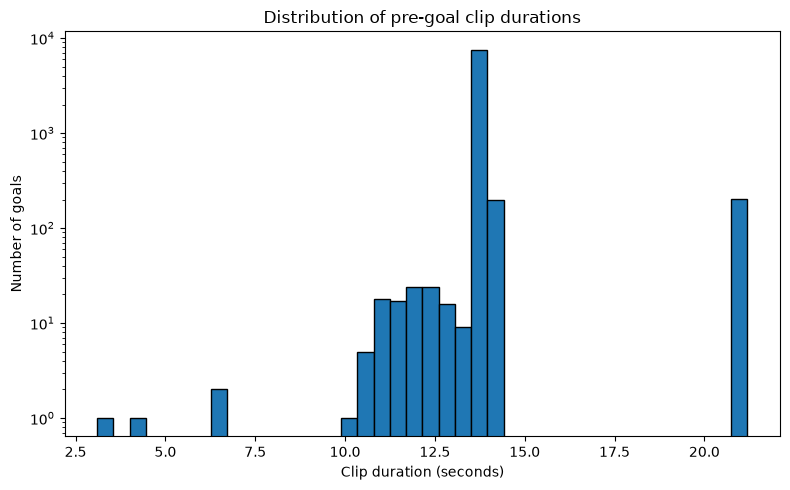

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(clip_stats["duration"].dropna(), bins=40, edgecolor="black")

ax.set_xlabel("Clip duration (seconds)")
ax.set_ylabel("Number of goals")
ax.set_title("Distribution of pre-goal clip durations")
ax.set_yscale("log")

plt.tight_layout()
plt.show()

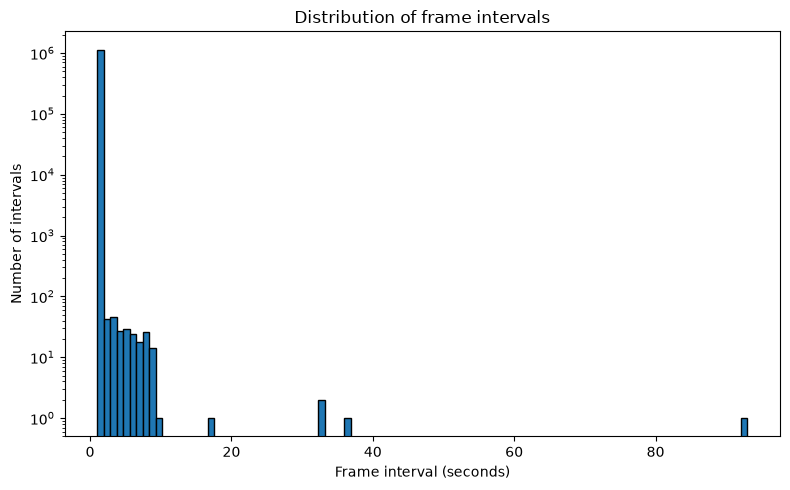

In [7]:
intervals = frame_times["frame_interval"].dropna()

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(intervals, bins=100, edgecolor="black")

ax.set_xlabel("Frame interval (seconds)")
ax.set_ylabel("Number of intervals")
ax.set_title("Distribution of frame intervals")
ax.set_yscale("log")

plt.tight_layout()
plt.show()

In [8]:
frame_times.nlargest(5, "frame_interval")
clip_stats["duration"].quantile(
    [0, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 1]
)

0.00     3.100000
0.10    13.800000
0.25    13.900000
0.50    13.900000
0.75    13.900000
0.90    13.900001
0.95    13.900001
1.00    21.200001
Name: duration, dtype: float32

In [9]:
# Include period in the tracking data
columns = [
    "game_id",
    "event_id",
    "period",
    "frame_idx",
    "time_stamp",
    "seconds_to_goal",
]

tracking = dataset.to_table(columns=columns).to_pandas()

clip_stats = (
    tracking
    .groupby(["game_id", "event_id"])
    .agg(
        period=("period", "first"),
        start_seconds=("seconds_to_goal", "min"),
        end_seconds=("seconds_to_goal", "max"),
        n_frames=("frame_idx", "nunique"),
    )
    .reset_index()
)

clip_stats["pre_goal_duration"] = -clip_stats["start_seconds"].clip(upper=0)
clip_stats["post_goal_duration"] = clip_stats["end_seconds"].clip(lower=0)
clip_stats["total_duration"] = (
    clip_stats["pre_goal_duration"] + clip_stats["post_goal_duration"]
)

In [10]:
display(
    clip_stats.groupby("period")["total_duration"]
    .agg(["count", "median", "mean", "max"])
)

display(
    clip_stats[clip_stats["total_duration"] > 18]
    .groupby("period")
    .size()
)

display(
    clip_stats[clip_stats["total_duration"] > 18][
        ["period", "pre_goal_duration", "post_goal_duration"]
    ].describe()
)

,count,median,mean,max
period,,,,
1,2301,13.9,13.865928,14.100000
2,2730,13.9,13.860476,14.200000
3,2825,13.9,13.860565,14.300000
4,206,20.9,20.701942,21.200001


period
4    201
dtype: int64

,period,pre_goal_duration,post_goal_duration
count,201.0,201.000000,201.000000
mean,4.0,11.181592,9.723383
std,0.0,1.054661,1.055225
min,4.0,7.200000,6.600000
25%,4.0,10.500000,9.100000
50%,4.0,11.100000,9.800000
75%,4.0,11.800000,10.400000
max,4.0,14.300000,13.700000


In [11]:
games_path = DATA_DIR / "games" / f"{SEASON}.parquet"
games = pd.read_parquet(games_path)

print(games.columns.tolist())
display(games.head())

['season', 'game_id', 'game_date', 'game_type', 'home_team_id', 'home_team_abbrev', 'away_team_id', 'away_team_abbrev']


,season,game_id,game_date,game_type,home_team_id,home_team_abbrev,away_team_id,away_team_abbrev
0,20252026,2025020001,2025-10-07,2,13,FLA,16,CHI
1,20252026,2025020002,2025-10-07,2,3,NYR,5,PIT
2,20252026,2025020003,2025-10-07,2,26,LAK,21,COL
3,20252026,2025020004,2025-10-08,2,10,TOR,8,MTL
4,20252026,2025020005,2025-10-08,2,15,WSH,6,BOS


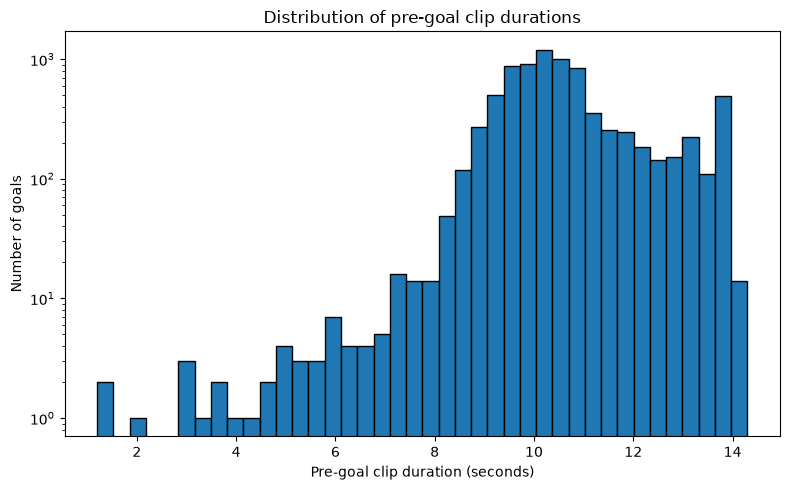

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    clip_stats["pre_goal_duration"].dropna(),
    bins=40,
    edgecolor="black"
)

ax.set_xlabel("Pre-goal clip duration (seconds)")
ax.set_ylabel("Number of goals")
ax.set_title("Distribution of pre-goal clip durations")
ax.set_yscale("log")

plt.tight_layout()
plt.show()